pip install numpy scipy pandas scikit-learn jupyter optuna umap-learn matplotlib opencv-python

## Теория

#### Для каких из уже изученных моделей актуально «проклятие размерности» и почему?
\
Линейная регрессия - сильно подвержена, потому что с ростом числа признаков модель начинает подстраиваться под шум. Если признаков больше, чем объектов, у неё появляется бесконечно много решений, и она выбирает такие, которые идеально предсказывают обучение, но не работают на новых данных. Шумовые признаки получают огромные веса.\
\
Логистическая регрессия - сильно подвержена (так же как и линейная регрессия). В высокой размерности любые точки можно разделить прямой, даже если между классами нет реальной разницы.\
\
Случайный лес -  менее подвержен, но тоже страдает. При огромном количестве бесполезных признаков деревья начинают случайно выявлять шумовые закономерности и включать их в правила. 

#### В чем разница между методом главных компонент и сингулярным разложением?
\
PCA - это задача, которая ищет оси при максимальной дисперсии.\
SVD - это алгоритм, он раскладывает любую матрицу на U·Σ·Vᵀ.\
\
PCA требует центрирования данных (вычитание среднего из исходных данных).\
SVD может работать с любой матрицей без центрирования.\
PCA можно вычислить через SVD. Если взять центрированную матрицу данных и применить к ней SVD, то правые сингулярные векторы  V (набор ортонормированных направлений в пространстве исходных признаков) окажутся главными компонентами PCA.

#### В чем разница между методом независимых компонент и сингулярным разложением?
\
SVD - ищет ортогональные направления, упорядоченные по сингулярным числам (коэффициентам важности каждой компоненты). Компоненты ортогональны, упорядочены по сингулярным числам. Применяется для любых данных.\
ICA - ищет статистически независимые компоненты. Компоненты не ортогональны, не упорядочены, а источники независимы и негауссовы. Применяется для неотрицательных данных (изображения, тексты).

#### Опишите структуру алгоритма локально-линейного вложения для уменьшения размерности.
\
LLE - алгоритм, который проецирует сложные данные на плоскость, сохраняя локальные связи между точками. Работает в три этапа.
\
Этап 1.\
Для каждой точки алгоритм находит K ближайших к ней точек (по обычному евклидову расстоянию).\
Получается словарь с точкой и списком соседей.\
\
Этап 2.\
Для каждой точки подбираются веса, чтобы через соседей можно было восстановить исходную точку (чем ближе сосед, тем больше его вес).\
!Сумма весов для каждой точки = 1.\
!Задача решается независимо для каждой точки.\
\
Этап 3.\
Алгоритм ищет новые координаты точек на плоскости некоторой размерности, чтобы те же самые веса как можно точнее восстанавливали каждую точку из её соседей. Решакм систему линейных уравнений.\
Условия:\
точки центрированы (среднее = 0)\
дисперсия по каждой новой оси фиксирована\
\
Математически:
1. W находится из локальных систем: (G + λI) w = 1 для каждой точки, где G - матрица Грама соседей, λ - небольшая регуляризация для устойчивости, 1 - вектор единиц.
2. M = (I - W)ᵀ(I - W) формируется как разреженная матрица.
3. Решается задача на собственные значения: M y = λ y. Выбираются векторы с наименьшими λ > 0.

!git add ml6.ipynb
!git commit -m "1 task"
!git push origin develop

In [77]:
import pandas as pd
import numpy as np
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import r2_score, classification_report
import optuna
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.manifold import TSNE, LocallyLinearEmbedding
import umap
import warnings
import time
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import glob
from sklearn.preprocessing import StandardScaler

## Подготовка данных

In [2]:
users = pd.read_csv("data/Users.csv")
ratings = pd.read_csv("data/Ratings.csv")

In [3]:
users.head(5)

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [4]:
ratings.head(5)

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [5]:
user_codes = ratings['User-ID'].astype('category').cat.codes
book_codes = ratings['ISBN'].astype('category').cat.codes
matrix = csr_matrix(
    (ratings['Book-Rating'], (user_codes, book_codes))
)

In [6]:
users['Age'] = users['Age'].fillna(users['Age'].median())

inx_unique_ratings = ratings['User-ID'].astype('category').cat.categories
inx_df_age = users.set_index('User-ID')['Age']
inx_users = inx_df_age.loc[inx_unique_ratings].values

In [7]:
inx_temp, inx_test = train_test_split(np.arange(matrix.shape[0]), test_size=0.2, random_state=21)
inx_train, inx_val = train_test_split(inx_temp, test_size=0.3, random_state=21)

x_train = matrix[inx_train]
x_val = matrix[inx_val]
x_test = matrix[inx_test]

y_train = inx_users[inx_train]
y_val = inx_users[inx_val]
y_test = inx_users[inx_test]

print("train: ", x_train.shape, y_train.shape)
print("valid: ", x_val.shape, y_val.shape)
print("test: ", x_test.shape, y_test.shape)

train:  (58958, 340556) (58958,)
valid:  (25268, 340556) (25268,)
test:  (21057, 340556) (21057,)


In [8]:
# scaler = StandardScaler()
# x_train = scaler.fit_transform(x_train)
# x_val = scaler.transform(x_val)
# x_test = scaler.transform(x_test)

## Обучение моделей

Оптимизация гиперпараметров у лг

In [9]:
%%time
lr = LinearRegression(fit_intercept=True)
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_val)
print("R2: ", r2_score(y_val, lr_pred))

R2:  -2.4236770776631915
CPU times: user 3min 41s, sys: 58.3 ms, total: 3min 41s
Wall time: 10.2 s


In [10]:
lr = LinearRegression(fit_intercept=False)
lr.fit(x_train, y_train)
lr_pred = lr.predict(x_val)
print("R2: ", r2_score(y_val, lr_pred))

R2:  -568.9188649941949


Оптимизация гиперпараметров у сл

In [11]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 20, 35, step=5),
        'max_depth': trial.suggest_int('max_depth', 2, 5),
        'random_state': 21,
        'n_jobs': -1
    }

    model = RandomForestRegressor(**params)
    model.fit(x_train, y_train)
    y_pred = model.predict(x_val)
    
    return r2_score(y_val, y_pred)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=10)

[I 2026-04-19 10:37:00,514] A new study created in memory with name: no-name-732e2baa-9237-4545-a031-f3fff34ff09e
[I 2026-04-19 10:37:11,217] Trial 0 finished with value: -0.0001644882891922439 and parameters: {'n_estimators': 30, 'max_depth': 2}. Best is trial 0 with value: -0.0001644882891922439.
[I 2026-04-19 10:37:21,703] Trial 1 finished with value: -0.0003733295125163405 and parameters: {'n_estimators': 30, 'max_depth': 5}. Best is trial 0 with value: -0.0001644882891922439.
[I 2026-04-19 10:37:33,965] Trial 2 finished with value: -0.00030289581506171004 and parameters: {'n_estimators': 25, 'max_depth': 4}. Best is trial 0 with value: -0.0001644882891922439.
[I 2026-04-19 10:37:44,549] Trial 3 finished with value: -0.00018241347503855643 and parameters: {'n_estimators': 30, 'max_depth': 4}. Best is trial 0 with value: -0.0001644882891922439.
[I 2026-04-19 10:37:56,260] Trial 4 finished with value: -0.0003056350391650309 and parameters: {'n_estimators': 35, 'max_depth': 4}. Best i

In [12]:
print("Лучшие параметры: ", study.best_params)
print("Лучший r2: ", study.best_value)

Лучшие параметры:  {'n_estimators': 30, 'max_depth': 2}
Лучший r2:  -0.0001644882891922439


Лучшие параметры:  {'n_estimators': 35, 'max_depth': 3}\
Лучший r2:  -0.0002330732031814442

In [13]:
%%time
rf = RandomForestRegressor(n_estimators = 35, max_depth = 3,random_state = 21, n_jobs = -1)
rf.fit(x_train, y_train)
rf_pred = rf.predict(x_val)
print("R2: ", r2_score(y_val, rf_pred))

R2:  -0.0002330732031814442
CPU times: user 3min 20s, sys: 114 ms, total: 3min 20s
Wall time: 10.6 s


## Сокращение размерности с помощью PCA и UMAP

In [14]:
%%time
pca = PCA(n_components=70, random_state=21)
x_train_pca = pca.fit_transform(x_train)
x_val_pca = pca.transform(x_val)
x_test_pca = pca.transform(x_test)

print(f"Дисперсия: {pca.explained_variance_ratio_.sum()}")

Дисперсия: 0.12561593935238452
CPU times: user 5min 56s, sys: 959 ms, total: 5min 57s
Wall time: 20.4 s


In [15]:
%%time
warnings.filterwarnings('ignore')
umap_model = umap.UMAP(
    n_components=2, # какое пространство
    random_state=21,
    n_neighbors=15, # количество соседей
    min_dist=0.1 # расстояние между точками
)

x_train_umap = umap_model.fit_transform(x_train_pca)
x_val_umap = umap_model.transform(x_val_pca)
x_test_umap = umap_model.transform(x_test_pca)

CPU times: user 13min 28s, sys: 2.33 s, total: 13min 30s
Wall time: 2min 31s


In [16]:
%%time
lr_pca = LinearRegression(fit_intercept=True)
lr_pca.fit(x_train_pca, y_train)
lr_pred = lr_pca.predict(x_val_pca)
print("R2: ", r2_score(y_val, lr_pred))

R2:  0.0034369507664336885
CPU times: user 1.62 s, sys: 55.8 ms, total: 1.68 s
Wall time: 159 ms


In [17]:
%%time
rf_pca = RandomForestRegressor(n_estimators = 35, max_depth = 3,random_state = 21, n_jobs = -1)
rf_pca.fit(x_train_pca, y_train)
rf_pred = rf_pca.predict(x_val_pca)
print("R2: ", r2_score(y_val, rf_pred))

R2:  0.012323499326145515
CPU times: user 30 s, sys: 94.2 ms, total: 30.1 s
Wall time: 1.75 s


In [18]:
%%time
# после pca - umap нашла Nan в данных
mask_val = ~np.isnan(x_val_umap).any(axis=1)
x_val_umap = x_val_umap[mask_val]
y_val_umap = y_val[mask_val]

lr_umap = LinearRegression(fit_intercept=True)
lr_umap.fit(x_train_umap, y_train)
lr_pred = lr_umap.predict(x_val_umap)
print("R2: ", r2_score(y_val_umap, lr_pred))

R2:  8.986421457335414e-05
CPU times: user 3.68 ms, sys: 4.31 ms, total: 7.99 ms
Wall time: 15.9 ms


In [19]:
%%time
rf_umap = RandomForestRegressor(n_estimators = 35, max_depth = 3,random_state = 21, n_jobs = -1)
rf_umap.fit(x_train_umap, y_train)
rf_pred = rf_umap.predict(x_val_umap)
print("R2: ", r2_score(y_val_umap, rf_pred))

R2:  0.0015485596656081846
CPU times: user 1.12 s, sys: 47.3 ms, total: 1.17 s
Wall time: 150 ms


После преобразования размерности в данных модели начали выполняться в десятки раз быстрее, но это только модели. Само сокращение размерности занимает больше времени, чем исзодное обучение. Результат выполнения остался примерно таким же. Хотя если посмотреть на дисперсию в PCA мы увидим, что сохранено только 12% информации от исходных. Такая экономия и памяти, и времени с неизменным итоговым результатом заслуживает внимания.

Время и метрика:\
Исходная:
1. Лин рег: ~10с и р2 ~ -2
2. Сл лес: ~9.7с и р2 ~ -0.0002
\
\
PCA:
1. Лин рег: ~(14c + 169мс) и р2 ~ 0.003
2. Сл лес: ~(14c + 242мс) и р2 ~ 0.01
\
\
UMAP:
1. Лин рег: ~(2м 34c + 10мс) и р2 ~ 0
2. Сл лес: ~(2м 34c + 170мс) и р2 ~ 0.001

## Визуализации

In [20]:
from sklearn.datasets import fetch_openml

# mnist dataset
x_mnist, y_mnist = fetch_openml('mnist_784',
                     version=1,
                     as_frame=True, # формат pandas
                     parser='auto',
                     return_X_y=True) #возвращает отдельные переменные
y_mnist = y_mnist.astype(int)

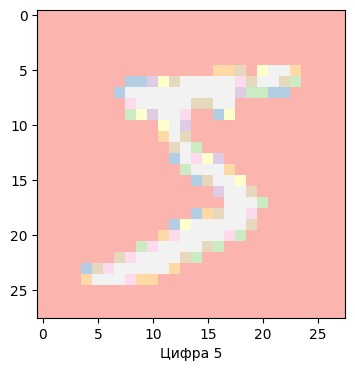

In [21]:
plt.figure(figsize=(4, 4))
plt.imshow(x_mnist.iloc[0].values.reshape(28, 28), cmap='Pastel1')
plt.xlabel(f"Цифра {y_mnist.iloc[0]}")
plt.show()

In [22]:
def show_mnist(x, y_mnist, name):
    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(x[:, 0], x[:, 1], c=y_mnist, cmap='Pastel1')
    plt.colorbar(scatter)
    plt.title(f'PCA проекция {name}')
    plt.show()

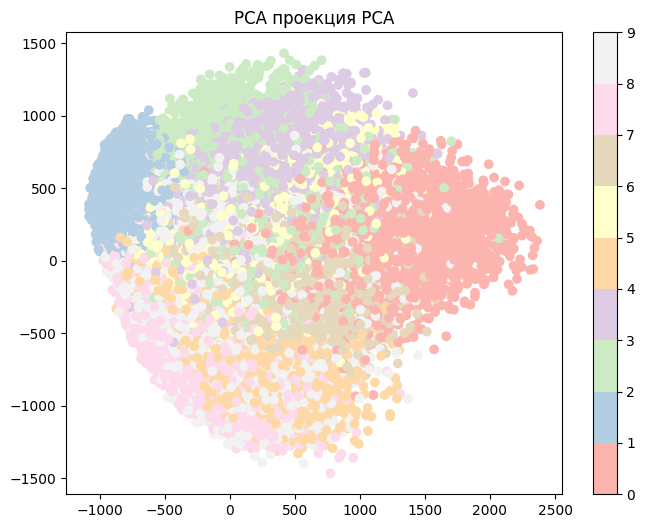

In [23]:
pca = PCA(n_components=2, random_state=21)
x_pca = pca.fit_transform(x_mnist)
show_mnist(x_pca, y_mnist, "PCA")

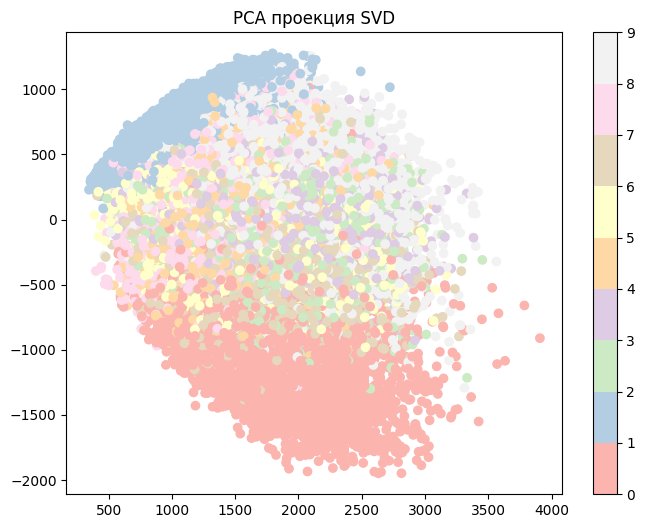

In [24]:
svd = TruncatedSVD(n_components=2)
x_svd = svd.fit_transform(x_mnist)
show_mnist(x_svd, y_mnist, "SVD")

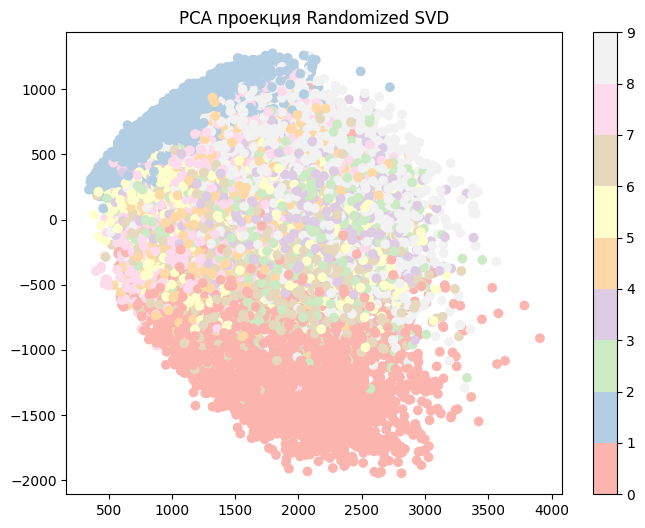

In [25]:
svd_rand = TruncatedSVD(n_components=2, algorithm='randomized')
x_svd_rand = svd_rand.fit_transform(x_mnist)
show_mnist(x_svd_rand, y_mnist, "Randomized SVD")

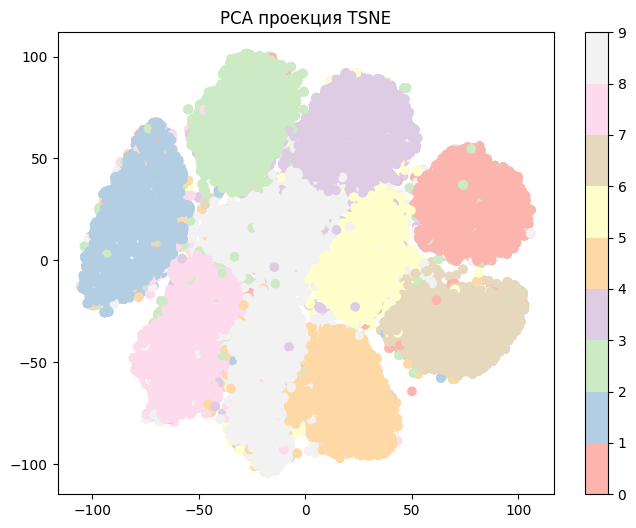

In [26]:
tsne = TSNE(n_components=2, random_state=21, n_jobs=-1)
x_tsne = tsne.fit_transform(x_mnist)
show_mnist(x_tsne, y_mnist, "TSNE")

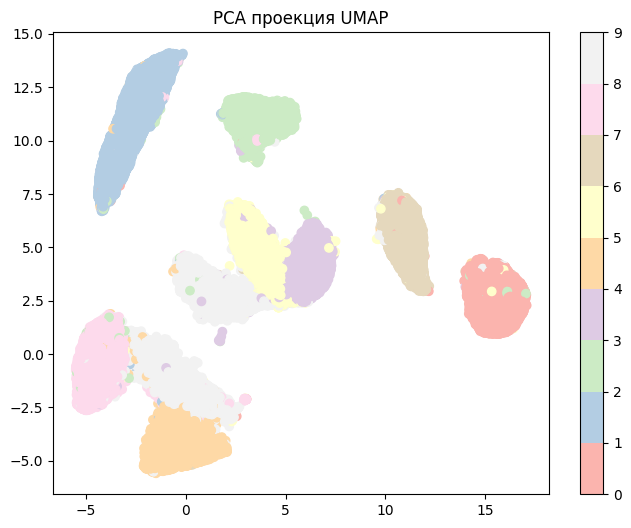

In [27]:
um = umap.UMAP(n_components=2, random_state=21)
x_umap = um.fit_transform(x_mnist)
show_mnist(x_umap, y_mnist, "UMAP")

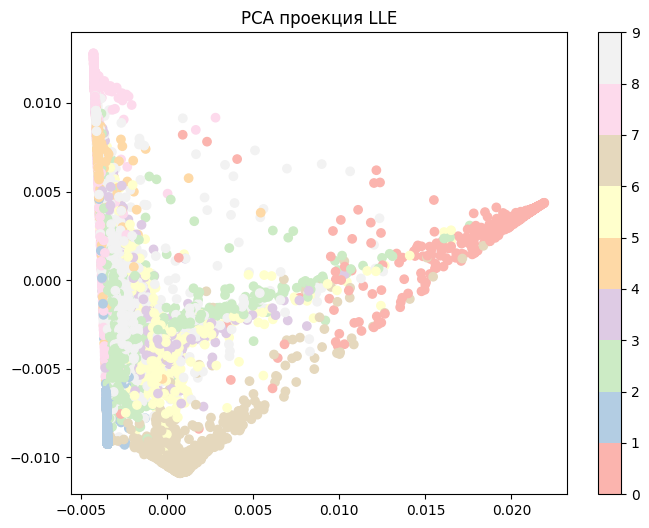

In [28]:
idx_for_lle = np.random.choice(len(x_mnist), 20000, replace=False)
x_for_lle = x_mnist.values[idx_for_lle]
y_for_lle = y_mnist.values[idx_for_lle]

lle = LocallyLinearEmbedding(n_components=2, n_neighbors=5, random_state=21, n_jobs=-1)
x_lle = lle.fit_transform(x_for_lle)
show_mnist(x_lle, y_for_lle, "LLE")

## Метрики сравнения алгоритмов

In [30]:
def change_alg(x, y):
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, stratify=y, random_state=21)
    model = RandomForestClassifier(max_depth = 5,random_state = 21)
    model.fit(x_train, y_train)
    pred = model.predict(x_test)
    return classification_report(y_test, pred)    

In [36]:
print('PCA')
print(change_alg(x_pca, y_mnist))

PCA
              precision    recall  f1-score   support

           0       0.70      0.74      0.72      1381
           1       0.90      0.92      0.91      1575
           2       0.41      0.04      0.07      1398
           3       0.47      0.56      0.51      1428
           4       0.38      0.50      0.43      1365
           5       0.00      0.00      0.00      1263
           6       0.28      0.49      0.36      1375
           7       0.45      0.58      0.51      1459
           8       0.26      0.49      0.34      1365
           9       0.34      0.11      0.17      1391

    accuracy                           0.45     14000
   macro avg       0.42      0.44      0.40     14000
weighted avg       0.43      0.45      0.41     14000



Модель показывает точность 45%.\
Цифра 1 распознаётся с F1-мерой 0.91, цифра 0 с F1 0.72. Остальные цифры имеют низкие показатели. Цифра 5 имеет F1-меру 0.00, то есть модель не предсказывает этот класс совсем. Цифра 2 имеет F1 0.07.\
\
PCA не разделяет классы, за исключением цифр 0 и 1.

In [37]:
print('SVD')
print(change_alg(x_svd, y_mnist))

SVD
              precision    recall  f1-score   support

           0       0.78      0.77      0.77      1381
           1       0.77      0.91      0.84      1575
           2       0.12      0.01      0.02      1398
           3       0.20      0.27      0.23      1428
           4       0.16      0.13      0.14      1365
           5       0.24      0.02      0.04      1263
           6       0.23      0.32      0.27      1375
           7       0.21      0.45      0.29      1459
           8       0.32      0.47      0.38      1365
           9       0.21      0.07      0.11      1391

    accuracy                           0.35     14000
   macro avg       0.32      0.34      0.31     14000
weighted avg       0.33      0.35      0.32     14000



Точность модели 35%.\
Цифра 1 имеет F1 0.84, цифра 0 имеет F1 0.77. Цифра 2 имеет F1 0.02, цифра 5 имеет F1 0.04. Остальные классы также имеют низкие значения.
\
\
SVD не обеспечивает разделение классов.

In [38]:
print('Randomized SVD')
print(change_alg(x_svd_rand, y_mnist))

Randomized SVD
              precision    recall  f1-score   support

           0       0.78      0.77      0.77      1381
           1       0.77      0.91      0.84      1575
           2       0.12      0.01      0.02      1398
           3       0.20      0.28      0.24      1428
           4       0.16      0.14      0.15      1365
           5       0.24      0.02      0.04      1263
           6       0.23      0.32      0.27      1375
           7       0.21      0.45      0.29      1459
           8       0.33      0.47      0.38      1365
           9       0.20      0.07      0.10      1391

    accuracy                           0.35     14000
   macro avg       0.32      0.34      0.31     14000
weighted avg       0.33      0.35      0.32     14000



Результаты почти совпадают с SVD.\
Точность 35%. Цифра 1 имеет F1 0.84, цифра 0 имеет F1 0.77. Цифры 2 и 5 имеют F1 0.02 и 0.04 соответственно.\
\
Разделение классов отсутствует.

In [39]:
print('TSNE')
print(change_alg(x_tsne, y_mnist))

TSNE
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1381
           1       0.97      0.99      0.98      1575
           2       0.97      0.94      0.95      1398
           3       0.98      0.94      0.96      1428
           4       0.97      0.95      0.96      1365
           5       0.89      0.97      0.93      1263
           6       0.98      0.98      0.98      1375
           7       0.96      0.91      0.93      1459
           8       0.91      0.90      0.90      1365
           9       0.92      0.94      0.93      1391

    accuracy                           0.95     14000
   macro avg       0.95      0.95      0.95     14000
weighted avg       0.95      0.95      0.95     14000



Точность модели 95%.\
Все цифры имеют F1-меру выше 0.90. Наименьший показатель у цифры 8 с F1 0.90.\
\
t-SNE хорошо разделяет все десять классов.

In [40]:
print('UMAP')
print(change_alg(x_umap, y_mnist))

UMAP
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1381
           1       0.96      0.99      0.98      1575
           2       0.98      0.96      0.97      1398
           3       0.96      0.96      0.96      1428
           4       0.98      0.95      0.96      1365
           5       0.92      0.92      0.92      1263
           6       0.97      0.99      0.98      1375
           7       0.96      0.97      0.97      1459
           8       0.94      0.90      0.92      1365
           9       0.93      0.95      0.94      1391

    accuracy                           0.96     14000
   macro avg       0.96      0.96      0.96     14000
weighted avg       0.96      0.96      0.96     14000



Точность модели 96%.\
Все цифры имеют F1-меру выше 0.92. Наименьший показатель у цифр 5 и 8 с F1 0.92.\
\
UMAP демонстрирует лучшее разделение классов среди всех методов.

In [41]:
print('LLE')
print(change_alg(x_lle, y_for_lle))

LLE
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       391
           1       0.97      0.98      0.98       456
           2       0.69      0.60      0.64       402
           3       0.57      0.81      0.67       407
           4       0.77      0.93      0.84       397
           5       0.66      0.39      0.49       358
           6       0.98      0.97      0.97       379
           7       0.95      0.79      0.86       424
           8       0.65      0.64      0.64       391
           9       0.86      0.87      0.86       395

    accuracy                           0.80      4000
   macro avg       0.80      0.80      0.79      4000
weighted avg       0.81      0.80      0.80      4000



Точность модели 80%.\
Цифры 1 и 6 имеют F1 0.98 и 0.97. Цифра 5 имеет F1 0.49, что значительно ниже остальных. Цифры 2 и 8 имеют F1 0.64.\
\
LLE разделяет классы хорошо, но уступает t-SNE и UMAP.

#### Итог по методам снижения размерности
Линейные методы PCA, SVD и Randomized SVD неэффективны для разделения рукописных цифр. Они сохраняют дисперсию, но не учитывают особенности формы (изгибы, пересечение линий), что приводит к точности 35-45% и неспособности распознавать большинство классов.\
\
Нелинейные методы t-SNE, UMAP и LLE сохраняют структуру данных, поэтому собирают похожие изображения в компактные кластеры. UMAP и t-SNE достигают точности 95-96%, почти идеально разделяя все десять цифр. LLE показывает результат 80% из-за стапых методов и высокой чувствительности к настройкам и шуму.

## Работа с рисунками

In [49]:
image1 = Image.open('data/Task_4/1.jpg').convert('L')
image2 = Image.open('data/Task_4/2.jpg').convert('L')
image3 = Image.open('data/Task_4/3.jpg').convert('L')

matrix1 = np.array(image1)
matrix2 = np.array(image2)
matrix3 = np.array(image3)

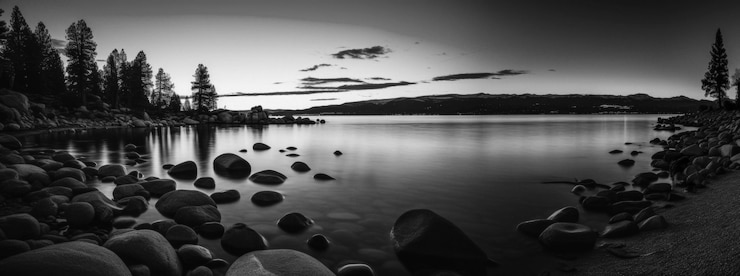

In [50]:
image1.show()

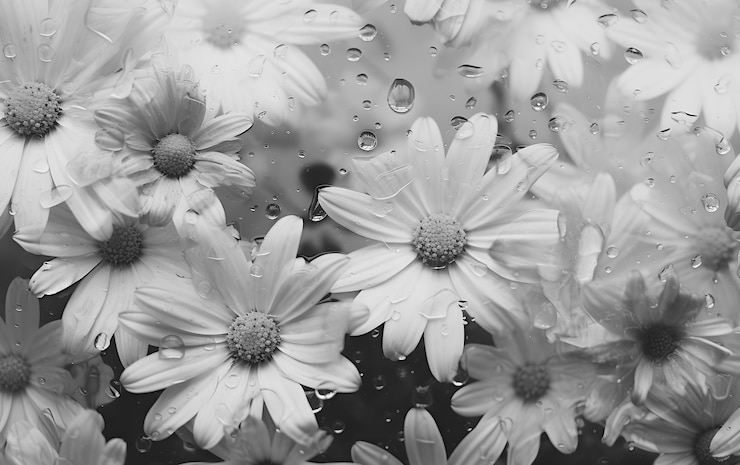

In [51]:
image2.show()

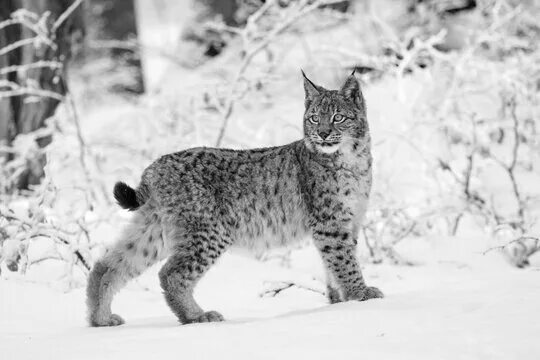

In [52]:
image3.show()

### Изображение заката

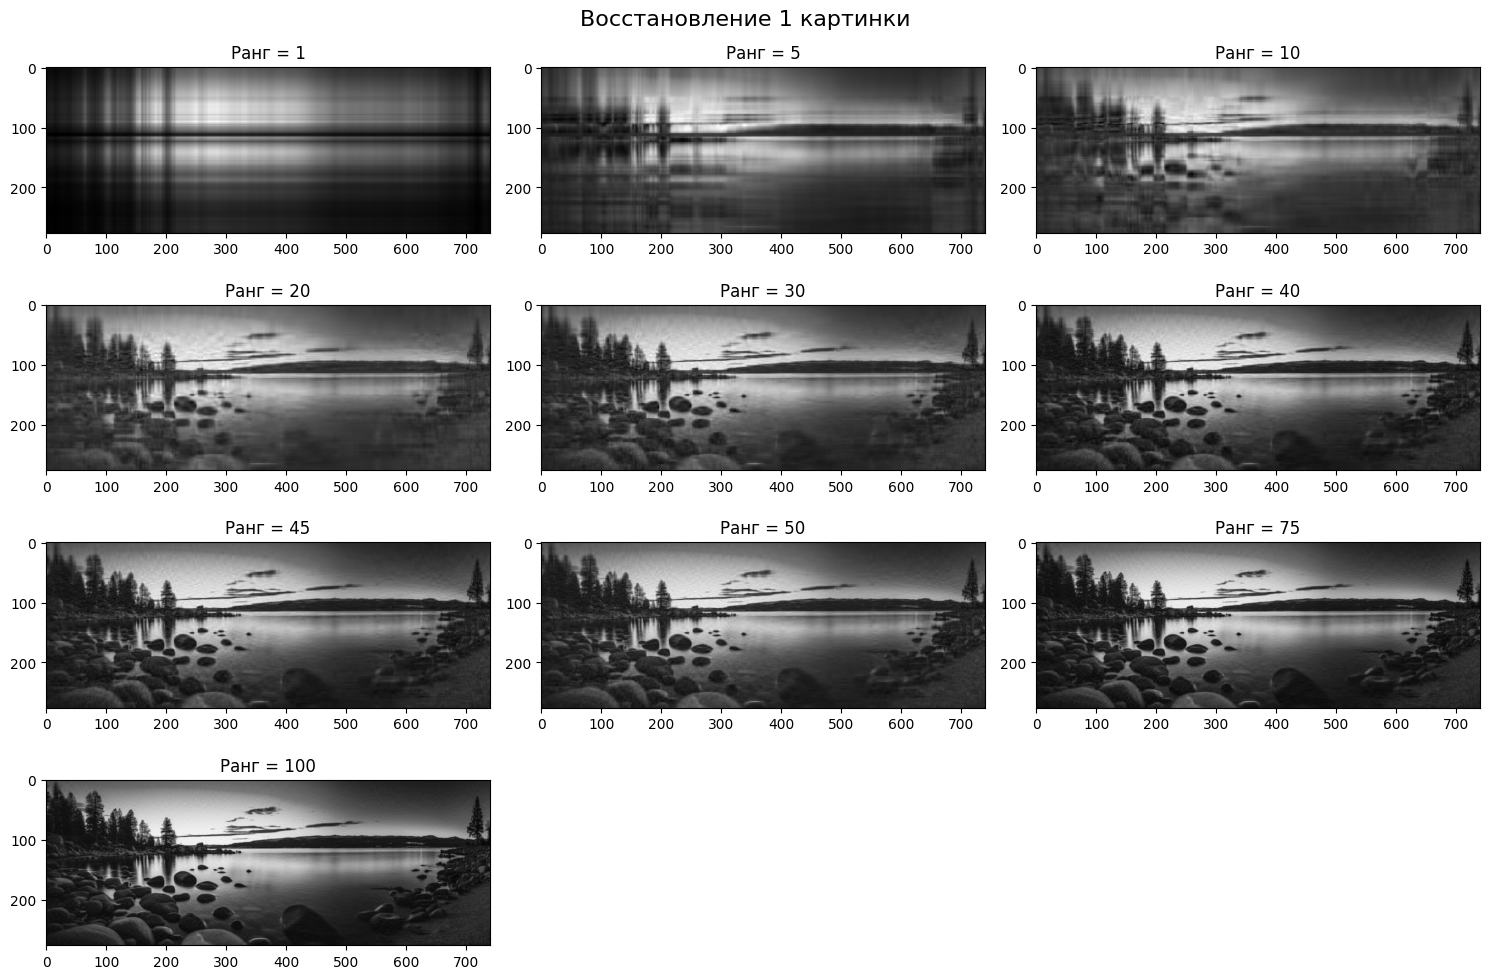

In [74]:
# раскладываю матрицу методом SVD
U, s, Vt = np.linalg.svd(matrix1, full_matrices=False)

ranks = [1, 5, 10, 20, 30, 40, 45, 50, 75, 100]

plt.figure(figsize=(15, 10))
for i, k in enumerate(ranks, 1):
    s_k = np.zeros_like(s)
    s_k[:k] = s[:k]
    
    svd_matrix = U @ np.diag(s_k) @ Vt

    plt.subplot(4, 3, i)
    plt.imshow(svd_matrix, cmap='gray')
    plt.title(f'Ранг = {k}')
plt.suptitle("Восстановление 1 картинки", fontsize=16)
plt.tight_layout()
plt.show()

Для понимания, что находится на рисунке достаточно 10-20 ранга, а для хорошего изображения подойдет 50 ранг.

**Объяснённая дисперсия - это доля информации, которую сохраняет аппроксимация с низким рангом (восстановление исходной матрицы с k сингулярных чисел).**

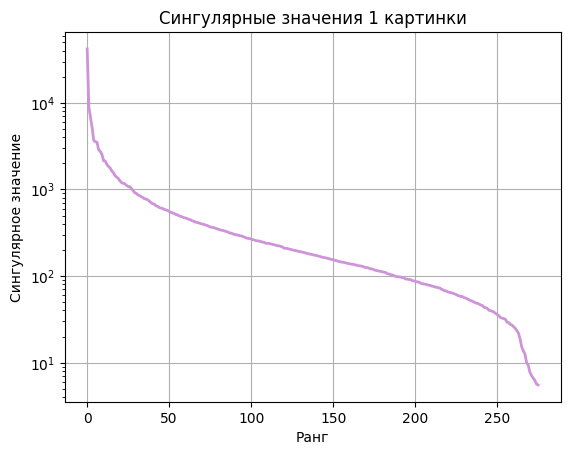

In [71]:
plt.semilogy(s, color='#CE93D8', lw=2)
plt.xlabel("Ранг")
plt.ylabel("Сингулярное значение")
plt.title("Сингулярные значения 1 картинки")
plt.grid()
plt.show()

### Изображение цветов

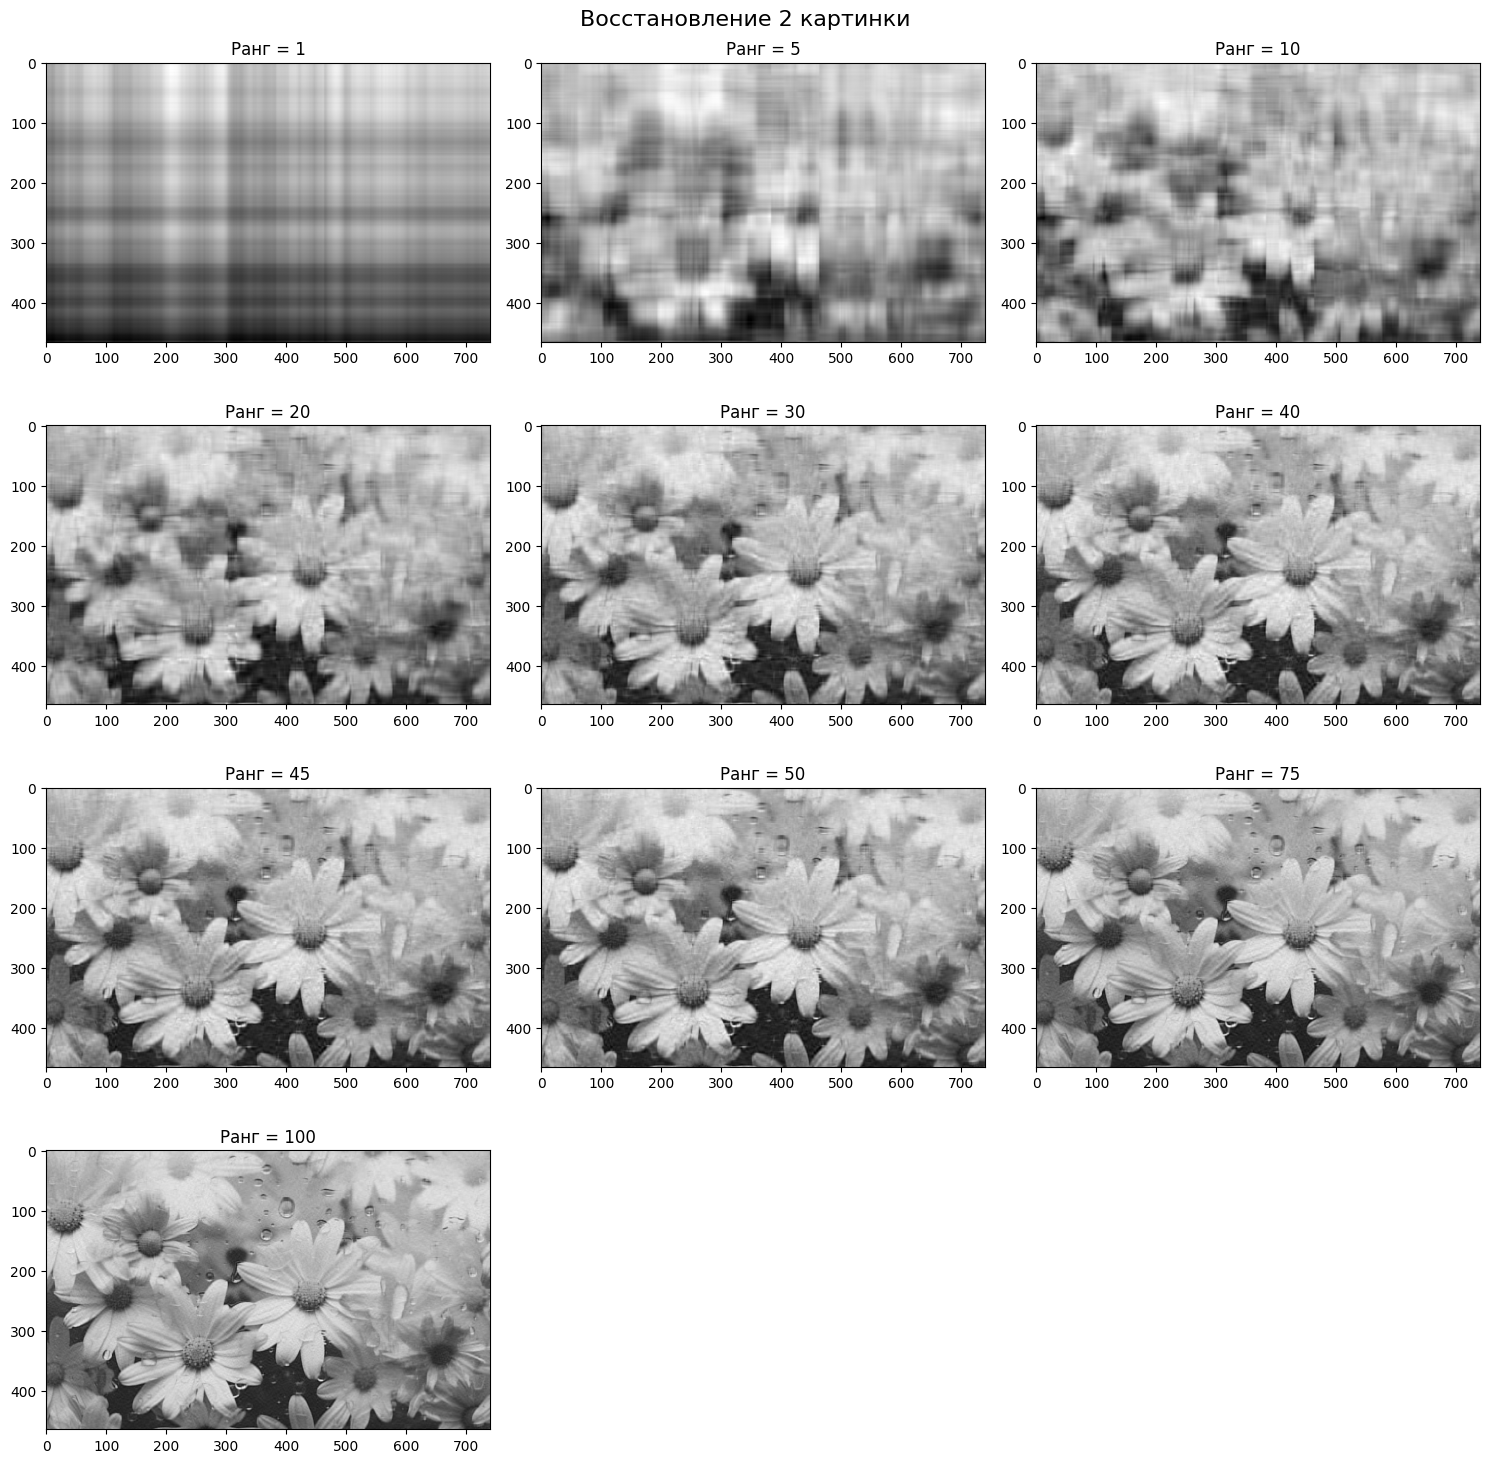

In [79]:
U, s, Vt = np.linalg.svd(matrix2, full_matrices=False)

ranks = [1, 5, 10, 20, 30, 40, 45, 50, 75, 100]

plt.figure(figsize=(15, 15))
for i, k in enumerate(ranks, 1):
    s_k = np.zeros_like(s)
    s_k[:k] = s[:k]
    
    svd_matrix = U @ np.diag(s_k) @ Vt

    plt.subplot(4, 3, i)
    plt.imshow(svd_matrix, cmap='gray')
    plt.title(f'Ранг = {k}')
plt.suptitle("Восстановление 2 картинки", fontsize=16)
plt.tight_layout()
plt.show()

Для понимания, что находится на рисунке достаточно 20 ранга, а для хорошего изображения подойдет 45-75 ранг.

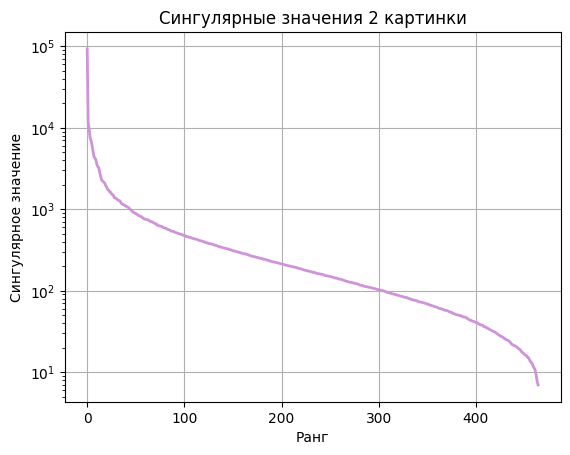

In [81]:
plt.semilogy(s, color='#CE93D8', lw=2)
plt.xlabel("Ранг")
plt.ylabel("Сингулярное значение")
plt.title("Сингулярные значения 2 картинки")
plt.grid()
plt.show()

### Изображение рыси

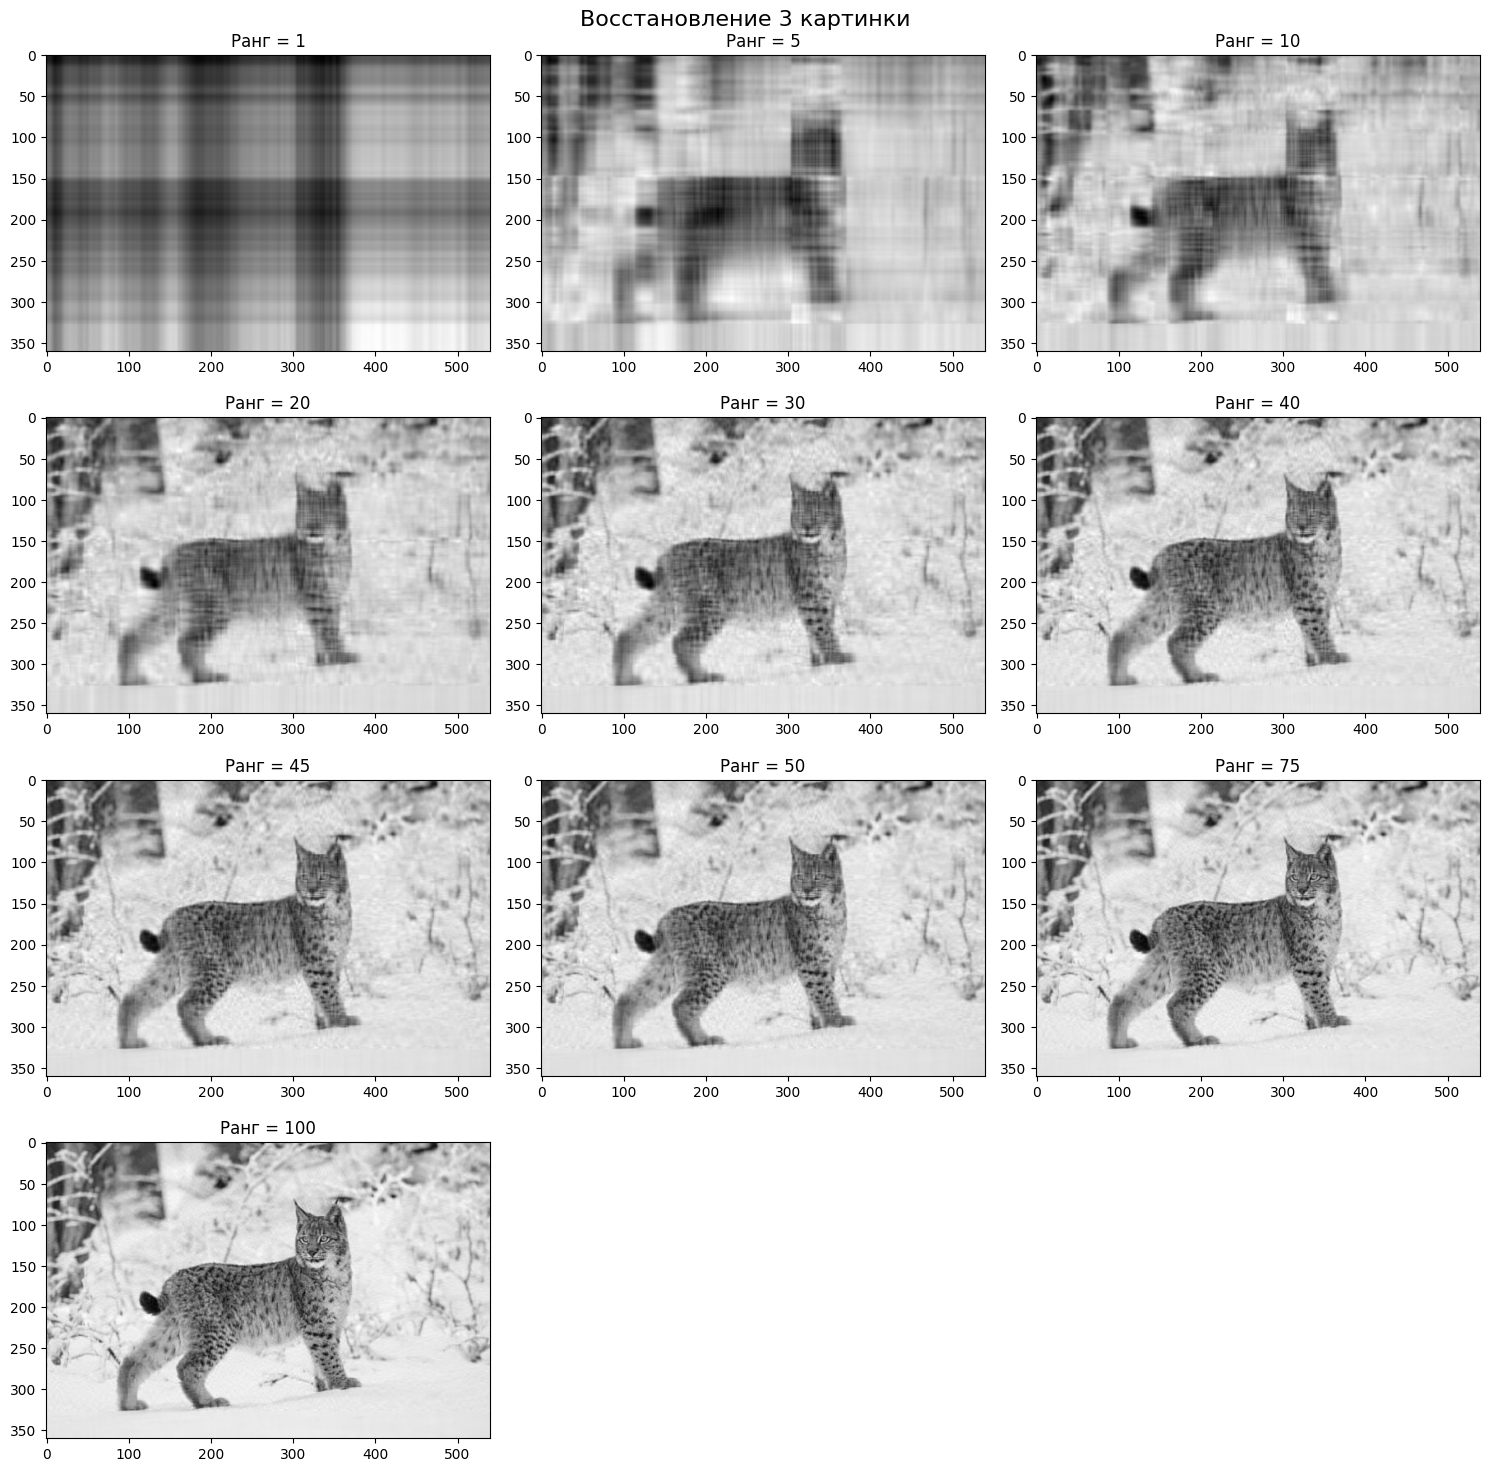

In [82]:
U, s, Vt = np.linalg.svd(matrix3, full_matrices=False)

ranks = [1, 5, 10, 20, 30, 40, 45, 50, 75, 100]

plt.figure(figsize=(15, 15))
for i, k in enumerate(ranks, 1):
    s_k = np.zeros_like(s)
    s_k[:k] = s[:k]
    
    svd_matrix = U @ np.diag(s_k) @ Vt

    plt.subplot(4, 3, i)
    plt.imshow(svd_matrix, cmap='gray')
    plt.title(f'Ранг = {k}')
plt.suptitle("Восстановление 3 картинки", fontsize=16)
plt.tight_layout()
plt.show()

Для понимания, что находится на рисунке достаточно 30 ранга, а для хорошего изображения подойдет 40-50 ранг.

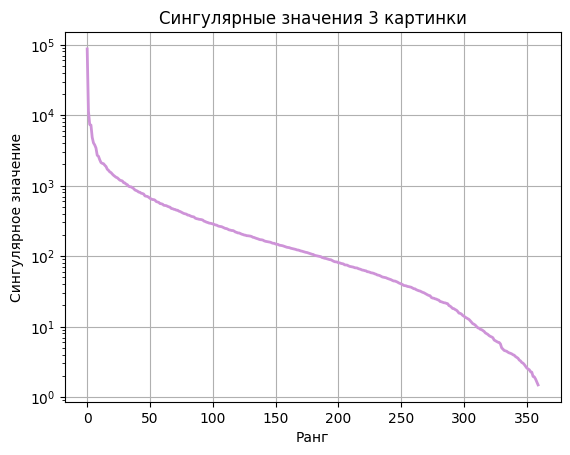

In [83]:
plt.semilogy(s, color='#CE93D8', lw=2)
plt.xlabel("Ранг")
plt.ylabel("Сингулярное значение")
plt.title("Сингулярные значения 3 картинки")
plt.grid()
plt.show()

Из графиков видно, что для идеального отображения разных картинок, нужно разное количество рангов (для 1: ~270, для 1: ~440, для 1: ~360).\
Это объясняется наличием мелких деталей, формы, яркости и многих друшиъ описательныъ характеристик картинки. Первое сингулярное число соответствует самой важной компоненте изображения (поэтому сингулярнок значение наивысшее). Она содержит общую яркость, контраст, грубую форму. Последующие компоненты добавляют детали: края, текстуру, мелкие элементы.

## Обнаружение фона с помощью SVD

In [27]:
video = cv2.VideoCapture('data/Video_008.avi')
width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

In [28]:
shots = list()
while True:
    quality, shot = video.read() # прочитан или нет, кадр
    if not quality: break    
    shots.append(shot)
video.release() #освобожденик памяти

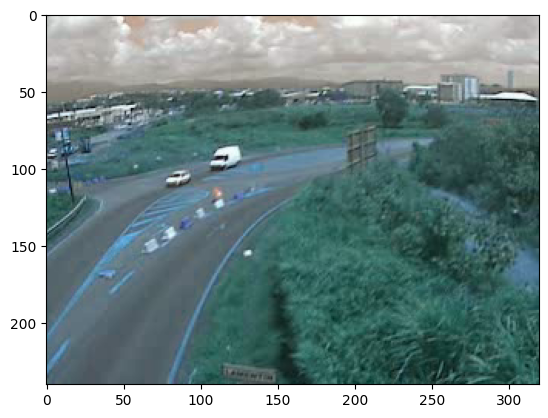

In [29]:
plt.imshow(shots[0])

In [25]:
video_matrix = np.array([frame.flatten() for frame in shots])
U, s, Vt = np.linalg.svd(video_matrix, full_matrices=False)

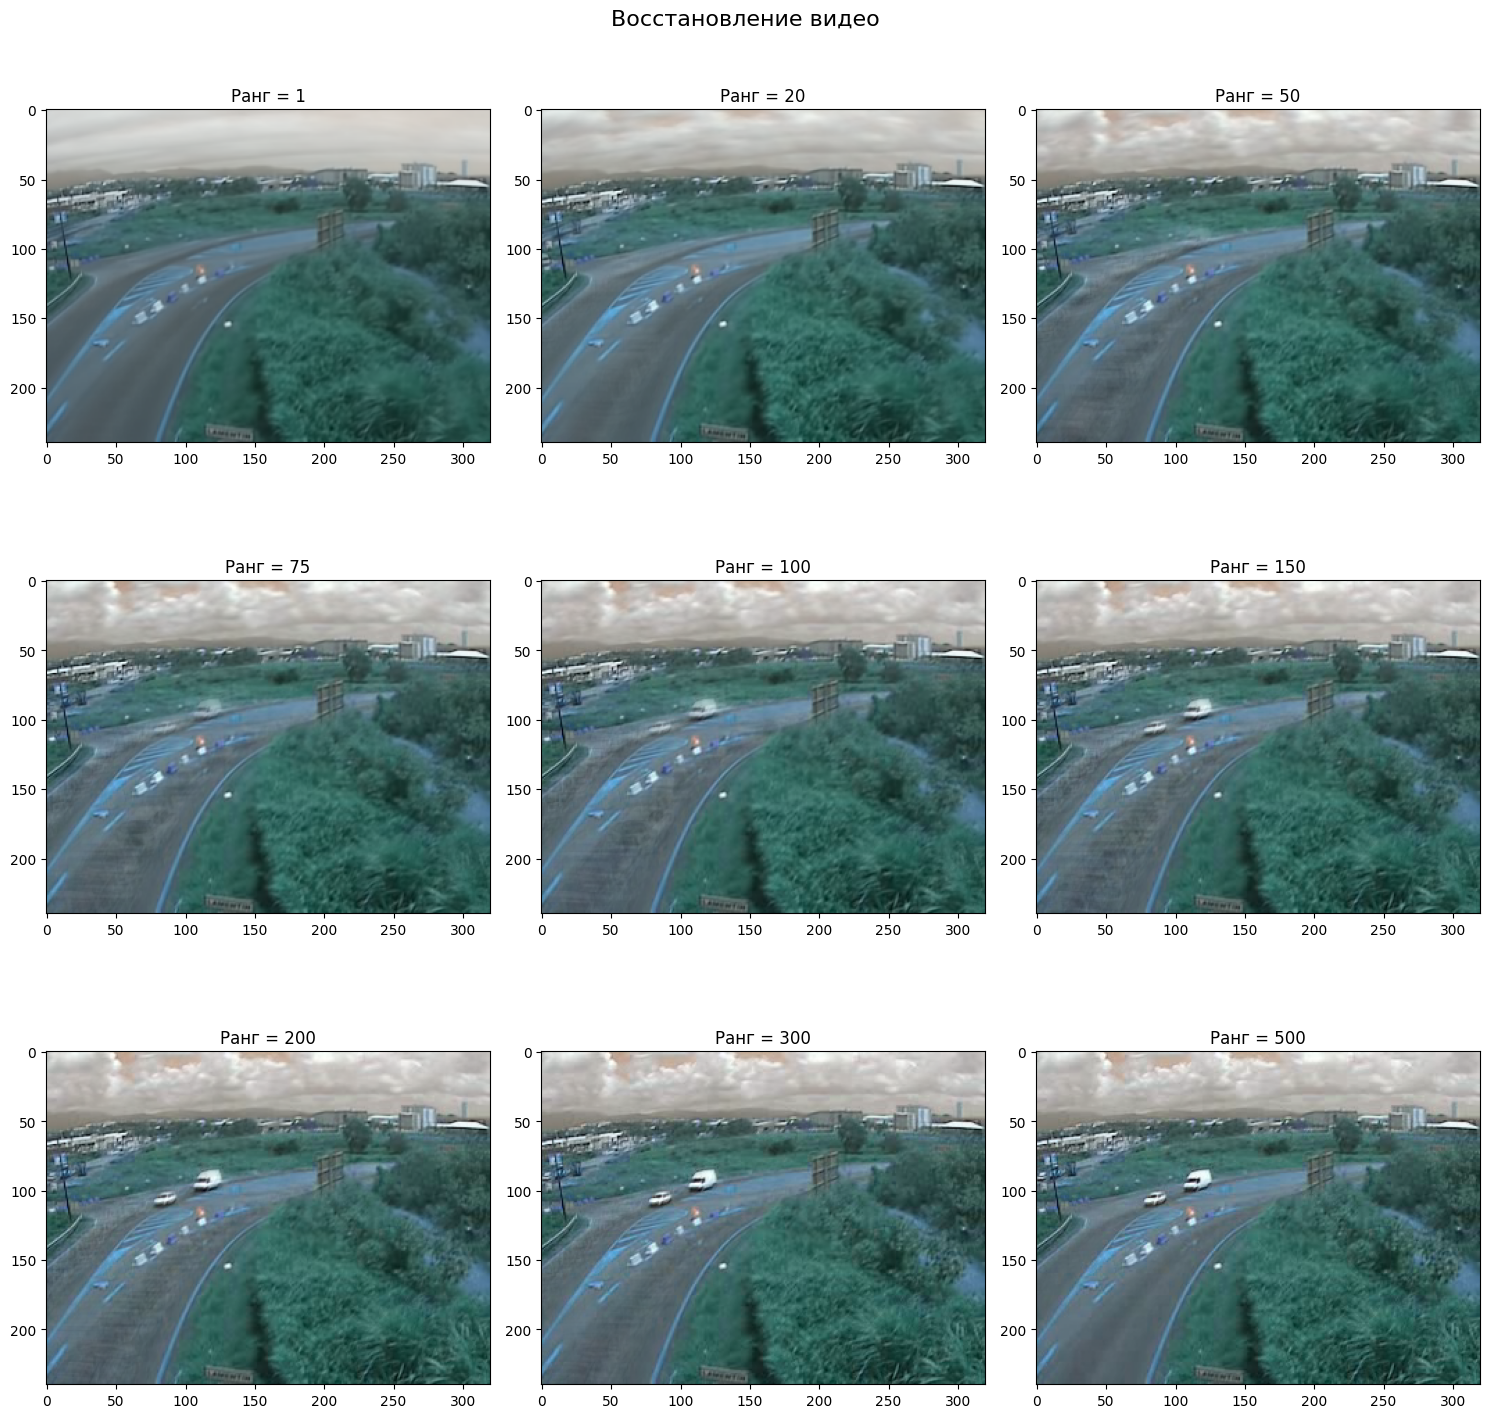

In [35]:
ranks = [1, 20, 50, 75, 100, 150, 200, 300, 500]

plt.figure(figsize=(15, 15))
for i, k in enumerate(ranks, 1):
    s_k = np.zeros_like(s)
    s_k[:k] = s[:k]
    
    svd_matrix = U @ np.diag(s_k) @ Vt

    plt.subplot(3, 3, i)
    first_image = svd_matrix[0].reshape(height, width, 3)
    first_image = np.clip(first_image, 0, 255).astype(np.uint8)
    plt.imshow(first_image)
    plt.title(f'Ранг = {k}')
plt.suptitle("Восстановление видео", fontsize=16)
plt.tight_layout()
plt.show()

Фон распознаётся с первого ранга, так как он статичен на всех кадрах, а вот машины совсем не видно. Адекватно можно ее разглядеть толькона 200-300 ранге.

## Бонусная часть

In [131]:
def load_faces(way):
    faces = []
    for file in glob.glob(way):
        img = Image.open(file).convert('L')
        img = img.resize((48, 48))
        faces.append(np.array(img).flatten())
    return np.array(faces)

x_sad = load_faces('data/img/sad/*.jpg')
x_happy = load_faces('data/img/happy/*.jpg')

In [132]:
x_all = np.vstack([x_sad, x_happy])
pca = PCA(n_components=80)
pca.fit(x_all)
pca_sad = pca.transform(x_sad)
pca_happy = pca.transform(x_happy)

mean_sad = pca_sad.mean(axis=0)
mean_happy = pca_happy.mean(axis=0)
emotion_vector = mean_happy - mean_sad
reverse_vector = mean_sad - mean_happy

In [133]:
sad_face = x_sad[12]
z = pca.transform(sad_face.reshape(1, -1))[0]
alpha = 3
z_new = z + alpha * emotion_vector

new_face = pca.inverse_transform(z_new.reshape(1, -1)).reshape(48, 48)

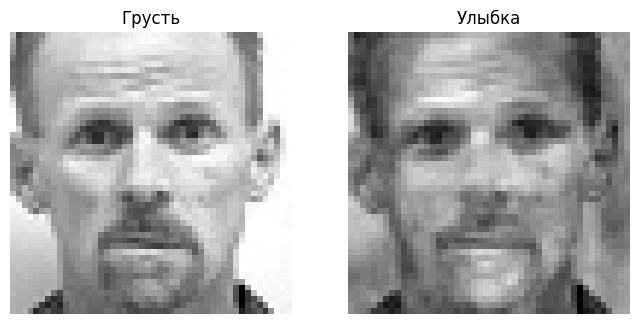

In [134]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(sad_face.reshape(48, 48), cmap='gray')
plt.title('Грусть')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(new_face, cmap='gray')
plt.title('Улыбка')
plt.axis('off')
plt.show()

In [135]:
happy_face = x_happy[18]
z = pca.transform(happy_face.reshape(1, -1))[0]
alpha = 2
z_new = z + alpha * reverse_vector
new_face = pca.inverse_transform(z_new.reshape(1, -1)).reshape(48, 48)

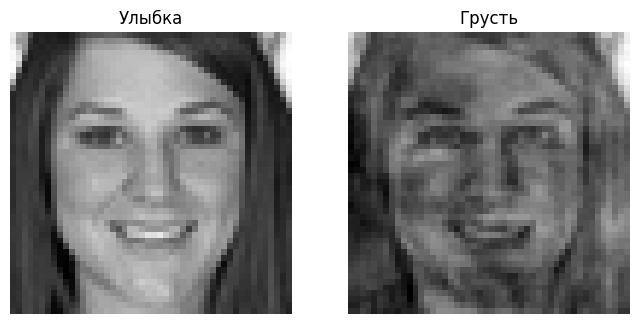

In [140]:
happy_face = x_happy[19]
z = pca.transform(happy_face.reshape(1, -1))[0]
alpha = 3
z_new = z + alpha * reverse_vector
new_face = pca.inverse_transform(z_new.reshape(1, -1)).reshape(48, 48)
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(happy_face.reshape(48, 48), cmap='gray')
plt.title('Улыбка')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(new_face, cmap='gray')
plt.title('Грусть')
plt.axis('off')
plt.show()

!git add
!git commit -m "видео"
!git push origin develop